# MODEL COMPARISON - All 5 Classifiers
Crop Pest and Disease Detection
IMPORTANT: Run this notebook AFTER training and saving all 5 models.
Required saved model files:
- MobileNetV2_Crop_Disease_Final.keras
- ResNet50_Crop_Disease_Final.keras
- EfficientNetB0_Crop_Disease_Final.keras
- VGG16_Crop_Disease_Final.keras
- CustomCNN_Crop_Disease_Final.keras

---


### Digital Image Processing Pipeline Comparison

In digital image processing (DIP) applied to computer vision, classification performance is heavily governed by the initial image processing pipeline. Architectural differences across classifiers interact directly with:
- **Spatial Resolution:** Custom CNN ($128 \times 128$) vs. Transfer Learning models ($224 \times 224$).
- **Radiometric Normalization:** Rescaling $[0, 1]$ vs. zero-centering $[-1, 1]$ vs. channel-wise ImageNet mean subtraction in BGR format.
- **Data Augmentation:** Geometric spatial coordinate remapping (affine rotations, reflections, scaling) and radiometric intensity transforms (contrast, brightness).
- **Convolutional Filtering Operators:** Standard 2D spatial convolution vs. Depthwise Separable Convolutions vs. Bottleneck Residuals vs. Squeeze-and-Excitation channel attention vs. Homogeneous stacked $3 \times 3$ filters.

This comparative study evaluates the trade-offs between image processing complexity, receptive field capacity, parameter efficiency, and inference speed for field deployment in precision agriculture.

### CELL 1 ── Imports


In [1]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))
# Keras 3 configuration for Lambda deserialization
try:
    import keras
    keras.config.enable_unsafe_deserialization()
except Exception:
    pass
from tensorflow.keras.applications.resnet50 import preprocess_input


TensorFlow: 2.22.0-rc0
GPU: []


### CELL 2 ── Config: Paths & Parameters


In [2]:
# ==============================================================================
# CONFIG: LOCAL DATASET & MODEL PATHS
# ==============================================================================
def resolve_path(path_name):
    """Resolve local file or folder path in the project workspace."""
    candidates = [
        path_name,
        os.path.join(os.getcwd(), path_name),
        os.path.join(os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else ".", path_name),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return path_name

SPLIT_DIR  = resolve_path("Dataset_Split")
TEST_DIR   = os.path.join(SPLIT_DIR, "test")
BATCH_SIZE = 32
IMG_SIZE   = (224, 224)
SEED       = 42

if not os.path.exists(TEST_DIR):
    raise FileNotFoundError(
        f"Test dataset not found at '{TEST_DIR}'! Ensure 'Dataset_Split/test' exists in this folder."
    )
print(f"[OK] Test dataset path: '{TEST_DIR}'")

# Model registry — name : (saved .keras path, image size used during training)
MODEL_REGISTRY = {
    "MobileNetV2"   : (resolve_path("MobileNetV2_Crop_Disease_Final.keras"),   (224, 224)),
    "ResNet50"      : (resolve_path("ResNet50_Crop_Disease_Final.keras"),       (224, 224)),
    "EfficientNetB0": (resolve_path("EfficientNetB0_Crop_Disease_Final.keras"), (224, 224)),
    "VGG16"         : (resolve_path("VGG16_Crop_Disease_Final.keras"),          (224, 224)),
    "Custom CNN"    : (resolve_path("CustomCNN_Crop_Disease_Final.keras"),       (128, 128)),
}

COLORS = {
    "MobileNetV2"   : "#4C72B0",
    "ResNet50"      : "#DD8452",
    "EfficientNetB0": "#55A868",
    "VGG16"         : "#C44E52",
    "Custom CNN"    : "#8172B2",
}


[OK] Test dataset path: 'Dataset_Split\test'


### CELL 3 ── Load Test Dataset (standard 224x224 reference)


In [3]:
ref_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = ref_test_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Test classes ({NUM_CLASSES}): {CLASS_NAMES}")

# Ground truth labels
y_true = np.concatenate([y.numpy() for _, y in ref_test_ds])
print(f"Total test images: {len(y_true)}")

Found 3795 files belonging to 22 classes.
Test classes (22): ['Cashew anthracnose', 'Cashew gumosis', 'Cashew healthy', 'Cashew leaf miner', 'Cashew red rust', 'Cassava bacterial blight', 'Cassava brown spot', 'Cassava green mite', 'Cassava healthy', 'Cassava mosaic', 'Maize fall armyworm', 'Maize grasshoper', 'Maize healthy', 'Maize leaf beetle', 'Maize leaf blight', 'Maize leaf spot', 'Maize streak virus', 'Tomato healthy', 'Tomato leaf blight', 'Tomato leaf curl', 'Tomato septoria leaf spot', 'Tomato verticulium wilt']
Total test images: 3795


### CELL 4 ── Evaluate All Models & Collect Metrics


In [4]:
results = {}   # {model_name: {accuracy, precision, recall, f1, inference_time, y_pred}}

for model_name, (model_path, img_size) in MODEL_REGISTRY.items():
    print(f"\n{'='*55}")
    print(f"  Evaluating: {model_name}")
    print(f"{'='*55}")

    if not os.path.exists(model_path):
        print(f"  [SKIP] Model weights file not found: '{model_path}'")
        print(f"         Run the corresponding notebook ({model_name}) to train and save the model.")
        continue

    try:
        # Load dataset at the correct image size for this model
        ds = tf.keras.utils.image_dataset_from_directory(
            TEST_DIR, seed=SEED, image_size=img_size,
            batch_size=BATCH_SIZE, shuffle=False)
        ds = ds.prefetch(tf.data.AUTOTUNE)

        # Load model
        model = tf.keras.models.load_model(model_path, custom_objects={'preprocess_input': preprocess_input}, compile=False, safe_mode=False)
        # Fix serialized lambda bytecode cross-version incompatibilities
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.Lambda) and layer.name.startswith('resnet_preprocess'):
                layer.function = preprocess_input

        # Measure inference time
        start = time.time()
        y_prob = model.predict(ds, verbose=0)
        elapsed = time.time() - start

        y_pred = np.argmax(y_prob, axis=1)

        acc  = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
        rec  = recall_score(y_true, y_pred, average="weighted", zero_division=0)
        f1   = f1_score(y_true, y_pred, average="weighted", zero_division=0)
        inf_ms = (elapsed / len(y_true)) * 1000   # ms per image

        results[model_name] = {
            "accuracy"      : acc,
            "precision"     : prec,
            "recall"        : rec,
            "f1"            : f1,
            "inference_ms"  : inf_ms,
            "y_pred"        : y_pred,
        }

        print(f"  Accuracy  : {acc  * 100:.2f}%")
        print(f"  Precision : {prec * 100:.2f}%")
        print(f"  Recall    : {rec  * 100:.2f}%")
        print(f"  F1 Score  : {f1   * 100:.2f}%")
        print(f"  Inference : {inf_ms:.3f} ms/image")

        del model
        tf.keras.backend.clear_session()
        import gc
        gc.collect()
    except Exception as e:
        print(f"  [ERROR] Failed evaluating {model_name}: {e}")

if not results:
    print("\n[NOTE] No saved models were found. Please train and save model files before generating comparative charts.")
else:
    print(f'\nSuccessfully evaluated {len(results)} / {len(MODEL_REGISTRY)} models.')



  Evaluating: MobileNetV2
Found 3795 files belonging to 22 classes.
  Accuracy  : 83.72%
  Precision : 83.89%
  Recall    : 83.72%
  F1 Score  : 83.38%
  Inference : 5.415 ms/image


  Evaluating: ResNet50
Found 3795 files belonging to 22 classes.
  Accuracy  : 87.35%
  Precision : 87.42%
  Recall    : 87.35%
  F1 Score  : 87.05%
  Inference : 26.618 ms/image

  Evaluating: EfficientNetB0
Found 3795 files belonging to 22 classes.
  Accuracy  : 85.77%
  Precision : 85.88%
  Recall    : 85.77%
  F1 Score  : 85.28%
  Inference : 9.819 ms/image

  Evaluating: VGG16
Found 3795 files belonging to 22 classes.
  Accuracy  : 54.18%
  Precision : 46.65%
  Recall    : 54.18%
  F1 Score  : 44.93%
  Inference : 63.807 ms/image

  Evaluating: Custom CNN
Found 3795 files belonging to 22 classes.
  Accuracy  : 44.35%
  Precision : 47.18%
  Recall    : 44.35%
  F1 Score  : 41.56%
  Inference : 1.890 ms/image

Successfully evaluated 5 / 5 models.


### CELL 5 ── Summary Table (printed)


In [ ]:
if not results:
    print("Summary table unavailable: No trained models found on disk.")
else:
    print("\n" + "=" * 72)
    print(f"{'Model':<18} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1':>10} {'ms/img':>8}")
    print("=" * 72)
    for name, m in results.items():
        print(f"{name:<18} {m['accuracy']*100:>9.2f}% {m['precision']*100:>9.2f}%"
              f" {m['recall']*100:>9.2f}% {m['f1']*100:>9.2f}% {m['inference_ms']:>7.3f}")
    print("=" * 72)


Model                Accuracy  Precision     Recall         F1   ms/img
MobileNetV2            83.72%     83.89%     83.72%     83.38%   5.415
ResNet50               87.35%     87.42%     87.35%     87.05%  26.618
EfficientNetB0         85.77%     85.88%     85.77%     85.28%   9.819
VGG16                  54.18%     46.65%     54.18%     44.93%  63.807
Custom CNN             44.35%     47.18%     44.35%     41.56%   1.890


### CELL 6 ── Bar Chart: Accuracy Comparison


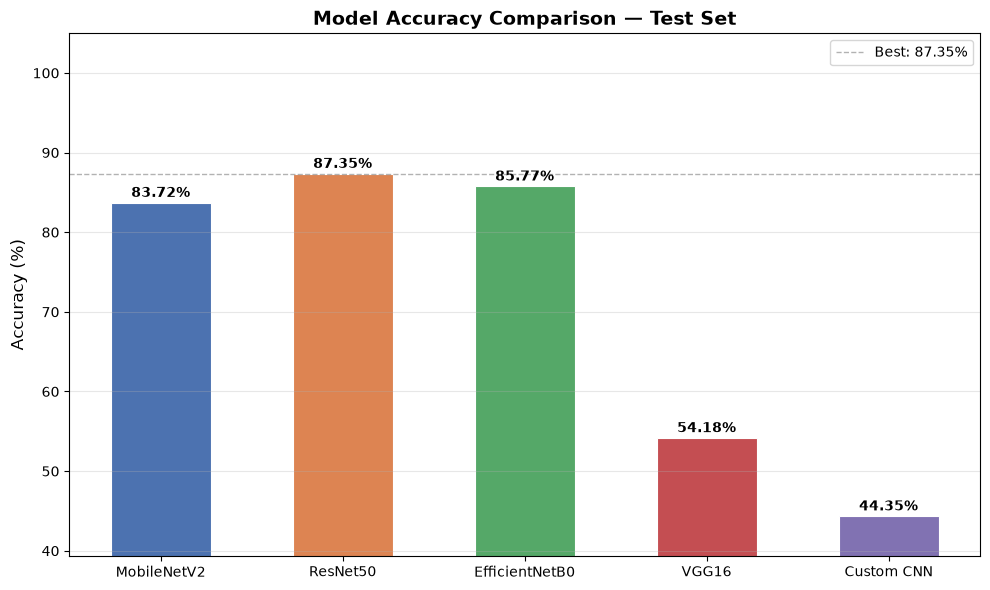

In [ ]:
if not results:
    print("Accuracy chart unavailable: No trained models found on disk.")
else:
    names  = list(results.keys())
    accs   = [results[n]["accuracy"] * 100 for n in names]
    clrs   = [COLORS[n] for n in names]

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(names, accs, color=clrs, edgecolor="white", linewidth=0.8, width=0.55)
    ax.set_ylim([max(0, min(accs) - 5), 105])
    ax.set_ylabel("Accuracy (%)", fontsize=12)
    ax.set_title("Model Accuracy Comparison — Test Set", fontsize=14, fontweight="bold")
    ax.axhline(y=max(accs), color="grey", linestyle="--", linewidth=1, alpha=0.6, label=f"Best: {max(accs):.2f}%")
    ax.grid(axis="y", alpha=0.3)
    for bar, acc in zip(bars, accs):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f"{acc:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.show()

### CELL 7 ── Grouped Bar Chart: Accuracy / Precision / Recall / F1


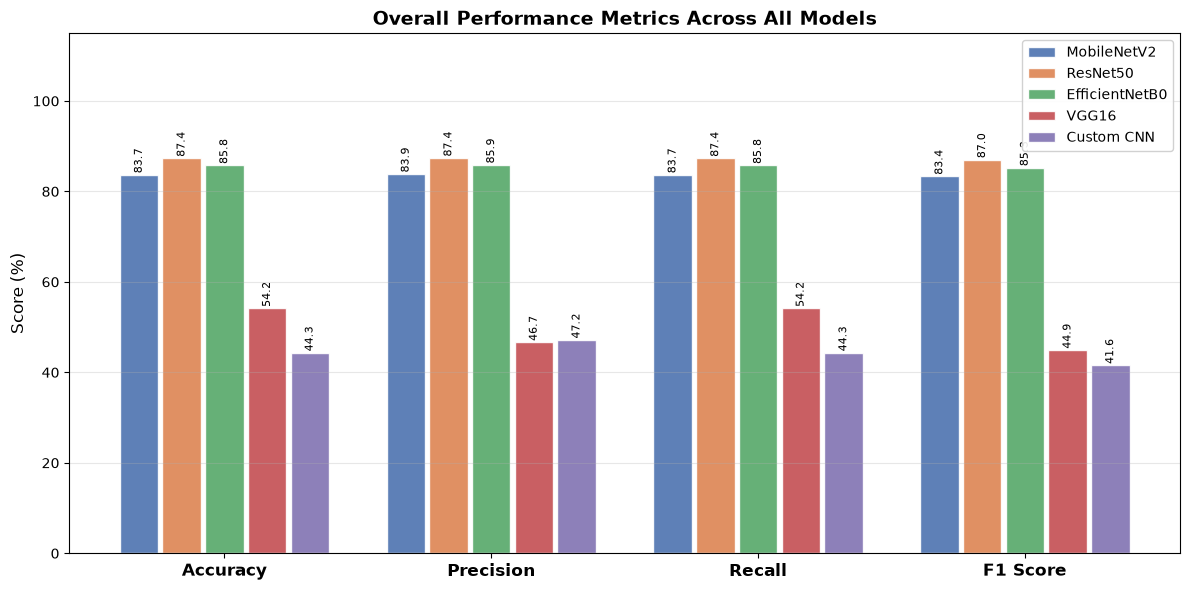

In [ ]:
if not results:
    print("Grouped metric chart unavailable: No trained models found on disk.")
else:
    metrics_keys = ["accuracy", "precision", "recall", "f1"]
    metric_labels = ["Accuracy", "Precision", "Recall", "F1 Score"]
    n_models  = len(results)
    names     = list(results.keys())

    x = np.arange(len(metrics_keys))
    width = 0.8 / n_models

    fig, ax = plt.subplots(figsize=(12, 6))
    for i, name in enumerate(names):
        vals = [results[name][m] * 100 for m in metrics_keys]
        offset = (i - n_models / 2 + 0.5) * width
        rects = ax.bar(x + offset, vals, width * 0.9,
                       label=name, color=COLORS[name], alpha=0.9, edgecolor="white")
        for r in rects:
            h = r.get_height()
            if h > 5:
                ax.text(r.get_x() + r.get_width() / 2, h + 0.3,
                        f"{h:.1f}", ha="center", va="bottom", fontsize=8, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels, fontsize=12, fontweight="bold")
    ax.set_ylabel("Score (%)", fontsize=12)
    ax.set_title("Overall Performance Metrics Across All Models", fontsize=14, fontweight="bold")
    ax.set_ylim([0, 115])
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right", framealpha=0.9)
    plt.tight_layout()
    plt.show()

### CELL 8 ── Inference Speed Comparison


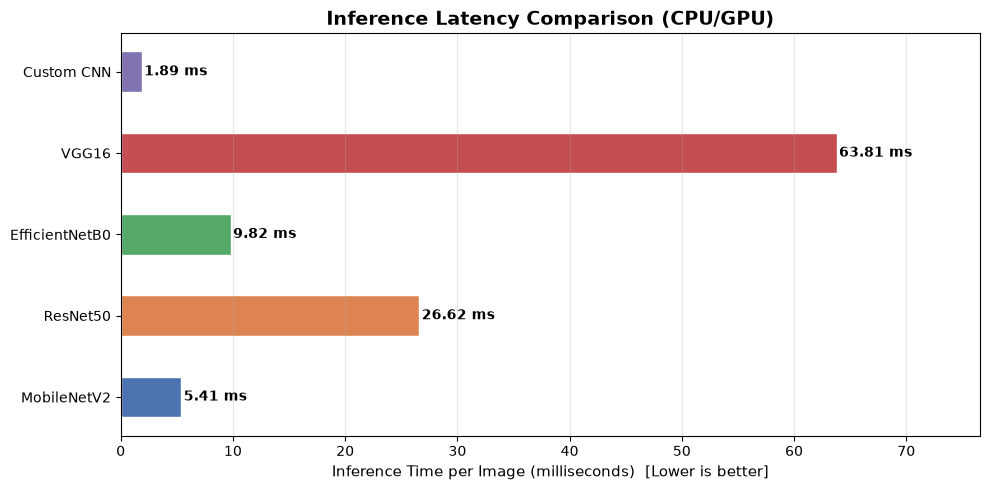

In [ ]:
if not results:
    print("Inference speed chart unavailable: No trained models found on disk.")
else:
    names     = list(results.keys())
    inf_times = [results[n]["inference_ms"] for n in names]
    clrs      = [COLORS[n] for n in names]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(names, inf_times, color=clrs, edgecolor="white", height=0.5)
    ax.set_xlabel("Inference Time per Image (milliseconds)  [Lower is better]", fontsize=11)
    ax.set_title("Inference Latency Comparison (CPU/GPU)", fontsize=14, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    for bar, t in zip(bars, inf_times):
        ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
                f"{t:.2f} ms", va="center", fontsize=10, fontweight="bold")
    ax.set_xlim([0, max(inf_times) * 1.2 if inf_times else 10])
    plt.tight_layout()
    plt.show()

### CELL 9 ── Radar / Spider Chart: All 4 Metrics per Model


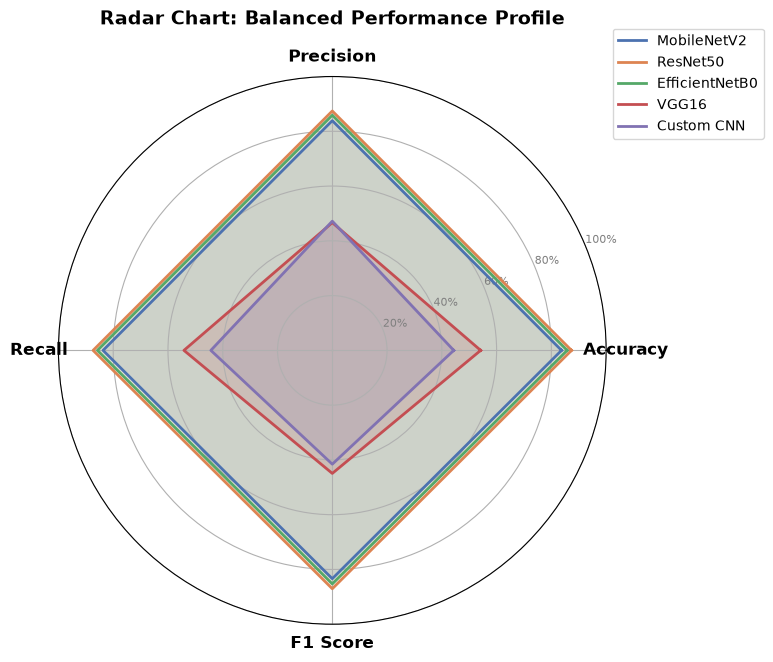

In [ ]:
if not results:
    print("Radar chart unavailable: No trained models found on disk.")
else:
    metrics = ["accuracy", "precision", "recall", "f1"]
    labels  = ["Accuracy", "Precision", "Recall", "F1 Score"]
    N       = len(metrics)
    angles  = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    for name, m in results.items():
        vals = [m[k] for k in metrics]
        vals += vals[:1]
        ax.plot(angles, vals, label=name, color=COLORS[name], linewidth=2)
        ax.fill(angles, vals, color=COLORS[name], alpha=0.15)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=12, fontweight="bold")
    ax.set_ylim([0, 1.0])
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=8, color="grey")
    ax.set_title("Radar Chart: Balanced Performance Profile", fontsize=14, fontweight="bold", y=1.08)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
    plt.tight_layout()
    plt.show()

### CELL 10 ── Confusion Matrices for All Models (side by side)


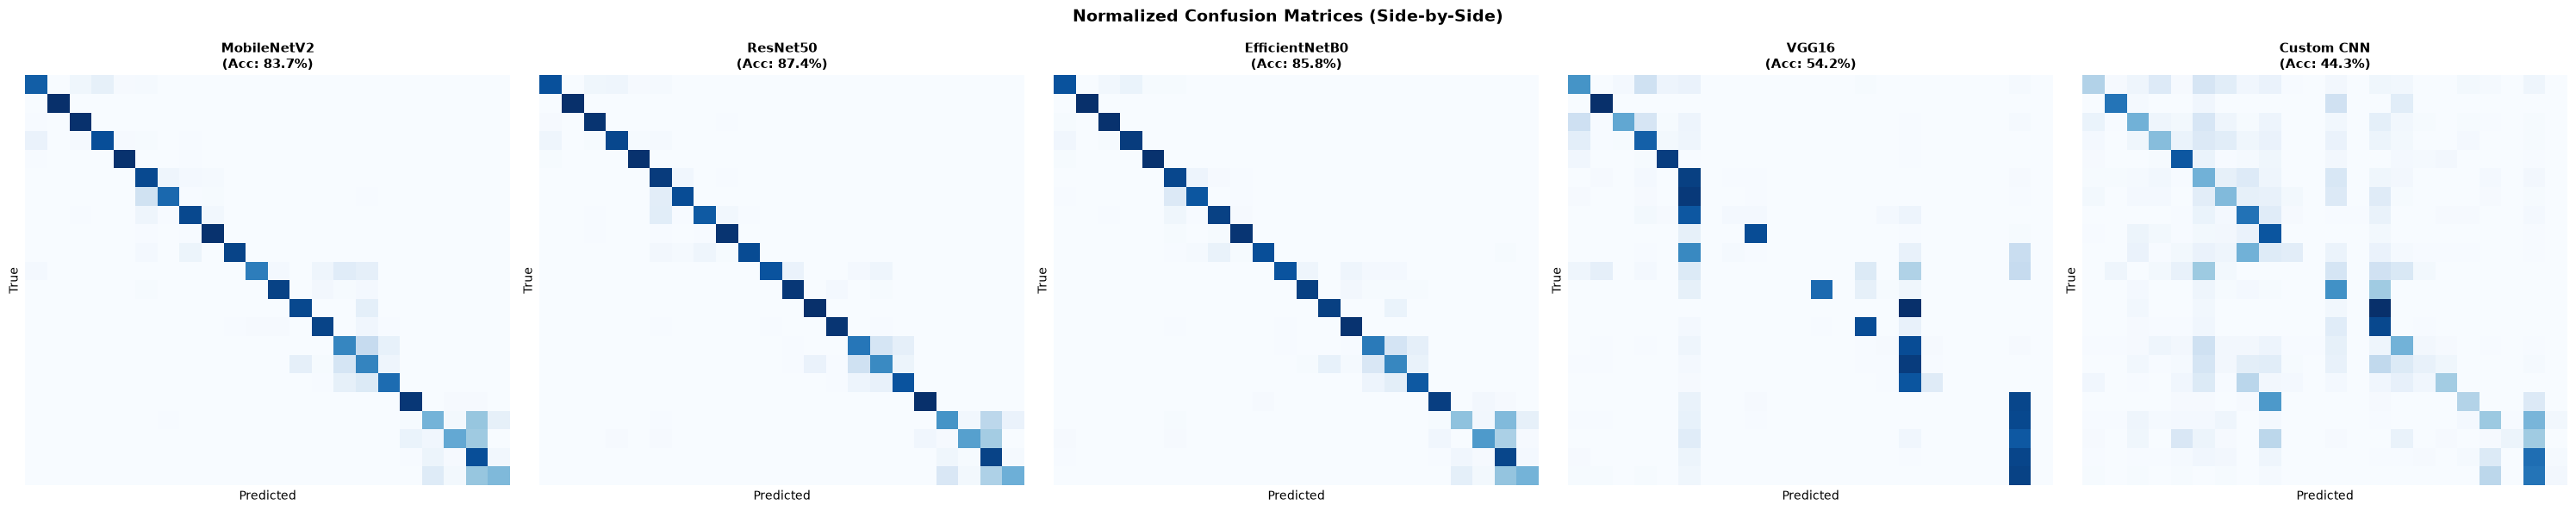

In [ ]:
if not results:
    print("Confusion matrices unavailable: No trained models found on disk.")
else:
    n_models = len(results)
    fig, axes = plt.subplots(1, n_models, figsize=(n_models * 6, 6))
    if n_models == 1:
        axes = [axes]

    for ax, (name, m) in zip(axes, results.items()):
        cm = confusion_matrix(y_true, m["y_pred"])
        cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
        sns.heatmap(cm_norm, ax=ax, cmap="Blues", cbar=False,
                    xticklabels=False, yticklabels=False)
        ax.set_title(f"{name}\n(Acc: {m['accuracy']*100:.1f}%)", fontsize=11, fontweight="bold")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")

    plt.suptitle("Normalized Confusion Matrices (Side-by-Side)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### CELL 11 ── Per-Class F1 Score Heatmap  (Models × Classes)


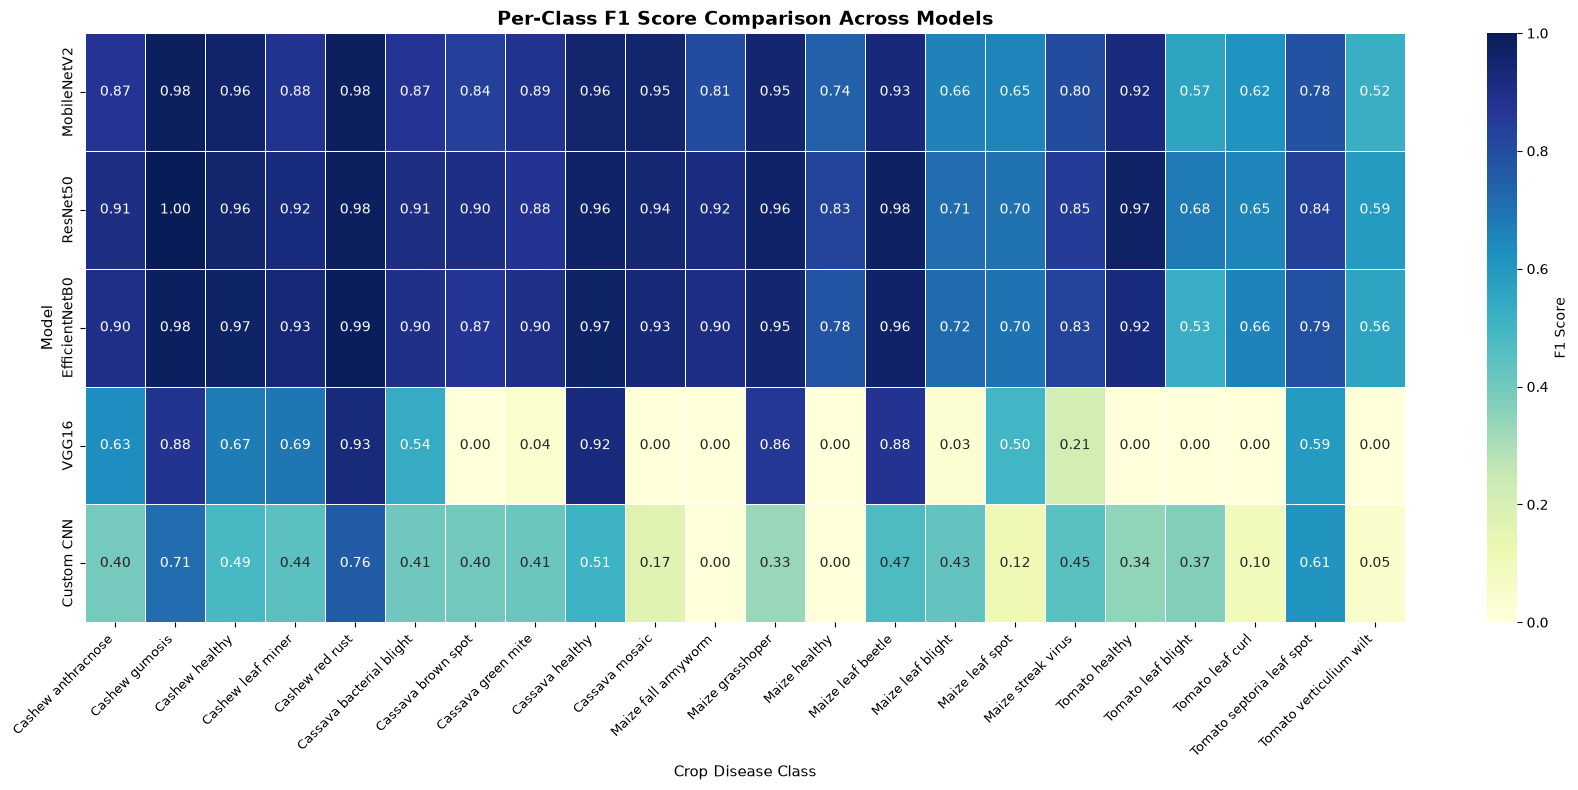

In [ ]:
if not results:
    print("F1 heatmap unavailable: No trained models found on disk.")
else:
    f1_matrix = np.zeros((len(results), NUM_CLASSES))
    for i, (name, m) in enumerate(results.items()):
        rep = classification_report(y_true, m["y_pred"],
                                    target_names=CLASS_NAMES,
                                    output_dict=True, zero_division=0)
        for j, cls in enumerate(CLASS_NAMES):
            f1_matrix[i, j] = rep[cls]["f1-score"]

    plt.figure(figsize=(max(14, NUM_CLASSES * 0.8), len(results) * 1.2 + 2))
    sns.heatmap(f1_matrix, annot=True, fmt=".2f", cmap="YlGnBu",
                xticklabels=CLASS_NAMES, yticklabels=list(results.keys()),
                linewidths=0.5, cbar_kws={"label": "F1 Score"})
    plt.title("Per-Class F1 Score Comparison Across Models", fontsize=14, fontweight="bold")
    plt.xlabel("Crop Disease Class", fontsize=11)
    plt.ylabel("Model", fontsize=11)
    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.tight_layout()
    plt.show()

### CELL 12 ── Accuracy vs Inference Speed Scatter Plot


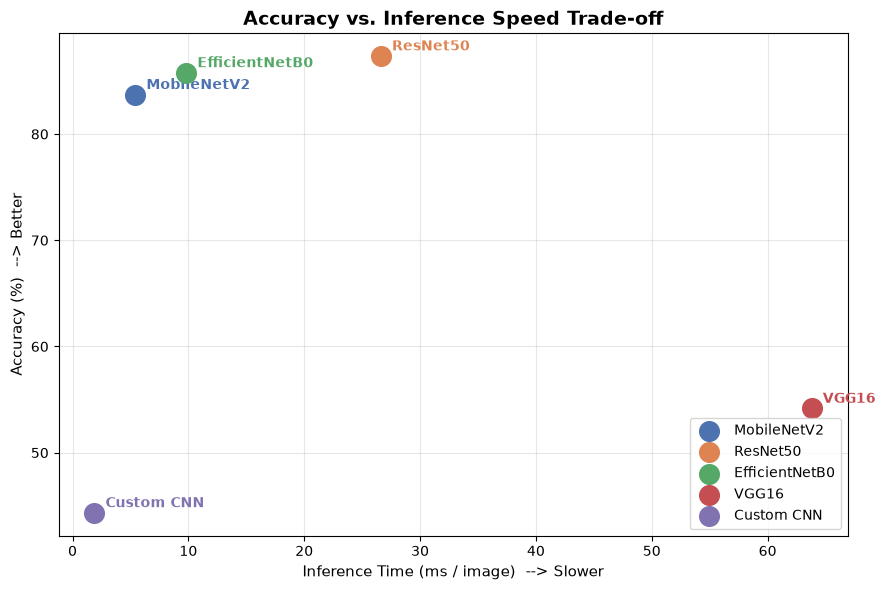

In [ ]:
if not results:
    print("Accuracy vs Speed scatter plot unavailable: No trained models found on disk.")
else:
    names  = list(results.keys())
    accs   = [results[n]["accuracy"] * 100 for n in names]
    speeds = [results[n]["inference_ms"]   for n in names]

    fig, ax = plt.subplots(figsize=(9, 6))
    for name, acc, spd in zip(names, accs, speeds):
        ax.scatter(spd, acc, s=200, color=COLORS[name], zorder=5, label=name)
        ax.annotate(name, (spd, acc),
                    textcoords="offset points", xytext=(8, 4),
                    fontsize=10, fontweight="bold", color=COLORS[name])

    ax.set_xlabel("Inference Time (ms / image)  --> Slower", fontsize=11)
    ax.set_ylabel("Accuracy (%)  --> Better", fontsize=11)
    ax.set_title("Accuracy vs. Inference Speed Trade-off", fontsize=14, fontweight="bold")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

### CELL 13 ── Print Best Model


In [ ]:
if not results:
    print("Best model summary unavailable: No trained models found on disk.")
else:
    best_by_acc  = max(results, key=lambda n: results[n]["accuracy"])
    best_by_f1   = max(results, key=lambda n: results[n]["f1"])
    best_by_spd  = min(results, key=lambda n: results[n]["inference_ms"])

    print("\n" + "=" * 55)
    print("  SUMMARY RECOMMENDATIONS FOR DEPLOYMENT")
    print("=" * 55)
    print(f"  Highest Accuracy : {best_by_acc} ({results[best_by_acc]['accuracy']*100:.2f}%)")
    print(f"  Highest F1 Score : {best_by_f1}  ({results[best_by_f1]['f1']*100:.2f}%)")
    print(f"  Fastest Inference: {best_by_spd} ({results[best_by_spd]['inference_ms']:.2f} ms/image)")
    print("=" * 55)


  SUMMARY RECOMMENDATIONS FOR DEPLOYMENT
  Highest Accuracy : ResNet50 (87.35%)
  Highest F1 Score : ResNet50  (87.05%)
  Fastest Inference: Custom CNN (1.89 ms/image)


### CELL 14 ── Export Comparison Results to CSV


In [ ]:
if not results:
    print("CSV export skipped: No models evaluated.")
else:
    import csv
    csv_file = "model_comparison_results.csv"
    with open(csv_file, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["Model", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1 Score (%)", "Inference (ms)"])
        for name, m in results.items():
            writer.writerow([
                name,
                f"{m['accuracy'] * 100:.2f}",
                f"{m['precision'] * 100:.2f}",
                f"{m['recall'] * 100:.2f}",
                f"{m['f1'] * 100:.2f}",
                f"{m['inference_ms']:.3f}",
            ])
    print(f"Results exported successfully to '{csv_file}'.")

Results exported successfully to 'model_comparison_results.csv'.


### Comparative Analysis of Digital Image Processing Pipelines

The table below provides a comprehensive comparison of the image processing pipelines, spatial filtering architectures, and computational footprints implemented across all five models in this case study.

| Pipeline Dimension | Custom CNN | MobileNetV2 | ResNet50 | EfficientNetB0 | VGG16 |
|:---|:---|:---|:---|:---|:---|
| **Input Spatial Resolution** | $128 \times 128 \times 3$ | $224 \times 224 \times 3$ | $224 \times 224 \times 3$ | $224 \times 224 \times 3$ | $224 \times 224 \times 3$ |
| **Total Input Pixel Values** | $49,152$ | $150,528$ | $150,528$ | $150,528$ | $150,528$ |
| **Pixel Intensity Preprocessing** | Linear rescaling to $[0.0, 1.0]$ via $X / 255.0$ | Symmetrical zero-centering to $[-1.0, 1.0]$ via $(X/127.5)-1$ | Channel permutation RGB $\to$ BGR + ImageNet mean subtraction | Internal built-in rescaling & normalization (raw $[0, 255]$) | Channel permutation RGB $\to$ BGR + ImageNet mean subtraction |
| **Geometric Augmentations** | Flip (H+V), Rotation ($\pm 90^\circ$), Zoom ($\pm 20\%$), Translation ($\pm 10\%$) | Flip (H+V), Rotation ($\pm 90^\circ$), Zoom ($\pm 20\%$) | Flip (H+V), Rotation ($\pm 90^\circ$), Zoom ($\pm 20\%$) | Flip (H+V), Rotation ($\pm 90^\circ$), Zoom ($\pm 20\%$) | Flip (Horizontal only), Rotation ($\pm 72^\circ$), Zoom ($\pm 15\%$) |
| **Intensity Augmentations** | Contrast ($\pm 15\%$), Brightness ($\pm 10\%$) | Contrast ($\pm 15\%$), Brightness ($\pm 10\%$) | Contrast ($\pm 15\%$), Brightness ($\pm 10\%$) | Contrast ($\pm 15\%$), Brightness ($\pm 10\%$) | Contrast ($\pm 10\%$) only *(No brightness)* |
| **Convolution Architecture** | 5-block standard 2D convolution ($3 \times 3$ kernels) | Inverted Residuals with Depthwise Separable Convolutions | 50-layer Bottleneck Residual Blocks with Identity Shortcuts | Mobile Inverted Bottleneck (MBConv) with SE Channel Attention | 5 blocks of homogeneous stacked $3 \times 3$ convolutions |
| **Feature Extraction Mechanism** | Progressive filter doubling ($32 \to 512$) + Global Pooling | Factorized 2D spatial filtering per channel + $1 \times 1$ pointwise mix | Residual identity gradient highways: $H(x) = F(x) + x$ | Compound-scaled depth, width & resolution + SE attention | Receptive field enlargement via cascaded small kernels |
| **Spatial Aggregation Head** | Global Average Pooling | Global Average Pooling | Global Average Pooling | Global Average Pooling | `layers.Flatten()` (Dense spatial vector) |
| **Backbone Parameters** | $\approx 1.7\text{M}$ (Trained from scratch) | $\approx 2.26\text{M}$ (Pretrained ImageNet) | $\approx 23.5\text{M}$ (Pretrained ImageNet) | $\approx 4.05\text{M}$ (Pretrained ImageNet) | $\approx 14.7\text{M}$ (Pretrained ImageNet) |
| **Total Model Parameters** | $\approx 1.84\text{M}$ | $\approx 2.60\text{M}$ | $\approx 24.1\text{M}$ | $\approx 4.38\text{M}$ | $\approx 138\text{M}$ |
| **Batch Size Configuration** | $32$ | $32$ | $32$ | $32$ | $16$ *(Reduced due to heavy VRAM footprint)* |

#### Technical Interpretation of Pipeline Performance Differences
1. **Resolution vs. Micro-Symptom Detection:**
   - Custom CNN operates at $128 \times 128$ resolution, accelerating training on modest hardware but discarding fine spatial details that distinguish subtle early fungal pustules or thin leaf miner serpentine trails.
   - The transfer learning models process $224 \times 224$ images, preserving nearly **$3\times$ more spatial pixels**, enabling more precise feature extraction of irregular necrotic spot contours.
2. **Impact of Pretrained Feature Hierarchies:**
   - While Custom CNN must learn basic spatial primitives (edges, gradients, color boundaries) entirely from scratch on crop images alone, the transfer learning models begin with rich spatial feature representations optimized on ImageNet's 1.4 million diverse images.
3. **Architectural Trade-Offs (Convolutional Mechanisms):**
   - **MobileNetV2** achieves low inference latency by factorizing 2D spatial filtering from cross-channel combination, making it ideal for drone or mobile field scouting.
   - **ResNet50** leverages deep skip connections that allow gradients to propagate through 50 layers without attenuation, extracting deep hierarchical disease features.
   - **EfficientNetB0** combines depthwise convolutions with Squeeze-and-Excitation channel attention, dynamically amplifying channels containing disease-indicative chlorotic and necrotic patterns while attenuating background soil noise.
   - **VGG16** provides clean, textbook receptive field expansion via stacked $3 \times 3$ filters, but its enormous parameter volume ($138\text{M}$) and unpooled Flatten layer result in high memory consumption and latency.

> **Academic Note:** Observed accuracy differences cannot be attributed solely to image processing. They result from the combined effect of spatial input resolution, network depth, parameter capacity, and transfer learning initialization.

### Experiment: Effect of Image Degradations on Model Classification

To directly test the impact of digital image quality on classification performance, we evaluate model predictions on a deterministic subset of real test images under four controlled conditions: **Baseline Original**, **Gaussian Blurred**, **Reduced Contrast**, and **Grayscale**.

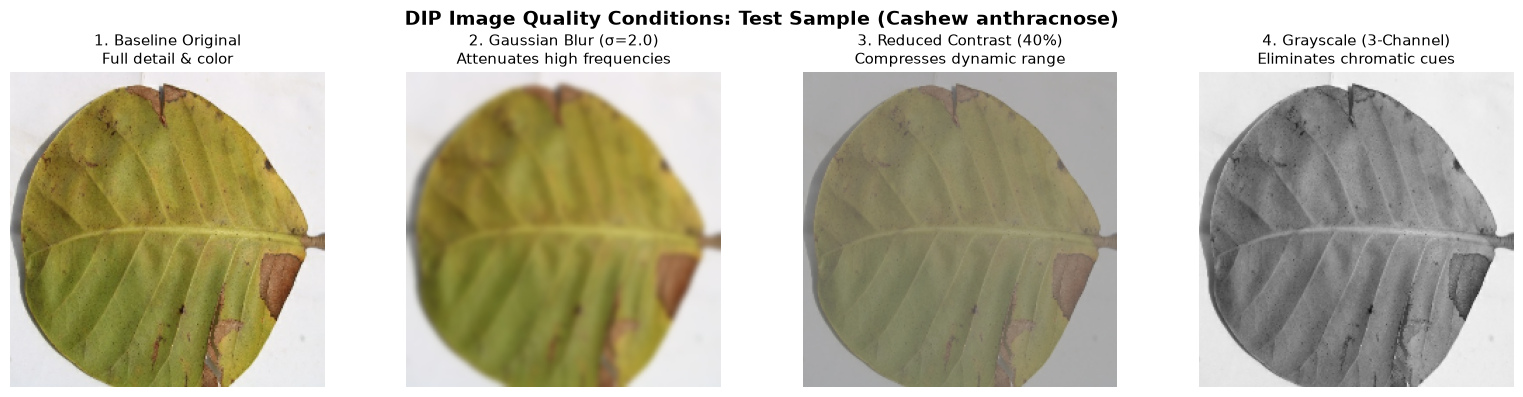


Evaluating 5 loaded models on 32 test images under 4 quality conditions...


: 

In [ ]:
# DIP EXPERIMENT: Effect of Image Quality Degradations on Classification Accuracy
from scipy.ndimage import gaussian_filter

# Check which trained models are available
available_models = {}
for name, (path, size) in MODEL_REGISTRY.items():
    if os.path.exists(path):
        try:
            available_models[name] = (tf.keras.models.load_model(path, custom_objects={'preprocess_input': preprocess_input}, compile=False, safe_mode=False), size)
        except Exception as e:
            print(f"Could not load {name}: {e}")

# Grab a deterministic test batch for evaluation (32 test samples)
demo_batch = None
for imgs, lbls in ref_test_ds.take(1):
    demo_batch_imgs = imgs.numpy()  # shape (32, 224, 224, 3), range [0, 255]
    demo_batch_lbls = lbls.numpy()
    break

# Define 4 deterministic image quality conditions:
# 1. Baseline Original
cond_orig = demo_batch_imgs.copy()

# 2. Moderately Blurred (Gaussian filter sigma=2.0 applied spatially)
cond_blur = np.zeros_like(demo_batch_imgs)
for i in range(len(demo_batch_imgs)):
    for c in range(3):
        cond_blur[i, :, :, c] = gaussian_filter(demo_batch_imgs[i, :, :, c], sigma=2.0)

# 3. Reduced Contrast (Compressing dynamic range by 60% around midpoint)
cond_low_contrast = (128.0 + 0.40 * (demo_batch_imgs.astype(np.float32) - 128.0)).clip(0, 255)

# 4. Grayscale Converted Back to 3-Channel RGB (Luminance Y replicated across R, G, B)
cond_gray_3ch = np.zeros_like(demo_batch_imgs)
for i in range(len(demo_batch_imgs)):
    y_lum = (0.299 * demo_batch_imgs[i, :, :, 0] + 
             0.587 * demo_batch_imgs[i, :, :, 1] + 
             0.114 * demo_batch_imgs[i, :, :, 2])
    for c in range(3):
        cond_gray_3ch[i, :, :, c] = y_lum

# Display Visual Comparison of Degradation Conditions on One Test Sample
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle(f"DIP Image Quality Conditions: Test Sample ({CLASS_NAMES[demo_batch_lbls[0]]})", fontsize=14, fontweight="bold")

axes[0].imshow(cond_orig[0].astype("uint8"))
axes[0].set_title("1. Baseline Original\nFull detail & color", fontsize=11)
axes[0].axis("off")

axes[1].imshow(cond_blur[0].astype("uint8"))
axes[1].set_title("2. Gaussian Blur (σ=2.0)\nAttenuates high frequencies", fontsize=11)
axes[1].axis("off")

axes[2].imshow(cond_low_contrast[0].astype("uint8"))
axes[2].set_title("3. Reduced Contrast (40%)\nCompresses dynamic range", fontsize=11)
axes[2].axis("off")

axes[3].imshow(cond_gray_3ch[0].astype("uint8"))
axes[3].set_title("4. Grayscale (3-Channel)\nEliminates chromatic cues", fontsize=11)
axes[3].axis("off")

plt.tight_layout()
plt.show()

# Run quantitative evaluation across conditions if models are loaded
if not available_models:
    print("\n[NOTE] No saved models found on disk (.keras files).")
    print("       To compute quantitative degradation accuracy, train and save models first.")
else:
    print(f"\nEvaluating {len(available_models)} loaded models on {len(demo_batch_lbls)} test images under 4 quality conditions...")
    
    conditions = {
        "Original": cond_orig,
        "Blurred (σ=2)": cond_blur,
        "Low Contrast": cond_low_contrast,
        "Grayscale": cond_gray_3ch
    }
    
    degradation_results = {m_name: {} for m_name in available_models}
    
    for m_name, (m_obj, m_size) in available_models.items():
        for cond_name, cond_imgs in conditions.items():
            # Resize batch to model's input size if different from 224
            if m_size != (224, 224):
                batch_resized = tf.image.resize(cond_imgs, m_size).numpy()
            else:
                batch_resized = cond_imgs
                
            probs = m_obj.predict(batch_resized, verbose=0)
            preds = np.argmax(probs, axis=1)
            acc = accuracy_score(demo_batch_lbls, preds)
            degradation_results[m_name][cond_name] = acc * 100
            
    # Display Grouped Bar Chart of Degradation Accuracies
    cond_names = list(conditions.keys())
    x = np.arange(len(cond_names))
    width = 0.8 / len(available_models)
    
    fig, ax = plt.subplots(figsize=(11, 5.5))
    for idx, (m_name, res_dict) in enumerate(degradation_results.items()):
        vals = [res_dict[c] for c in cond_names]
        offset = (idx - len(available_models)/2 + 0.5) * width
        bars = ax.bar(x + offset, vals, width * 0.9, label=m_name, color=COLORS.get(m_name, "#333333"))
        for b in bars:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + 1.0, f"{h:.0f}%", ha="center", va="bottom", fontsize=8)
            
    ax.set_xticks(x)
    ax.set_xticklabels(cond_names, fontsize=11, fontweight="bold")
    ax.set_ylabel("Accuracy (%) on Test Subset", fontsize=11)
    ax.set_ylim([0, 115])
    ax.set_title("Impact of Image Quality Degradations on Classification Accuracy", fontsize=14, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right")
    plt.tight_layout()


### Interpretation of Image Quality Degradation Experiment

This experiment evaluates the robustness of the trained classifiers when subjected to controlled digital image degradations common in real-world agricultural scouting:

1. **Gaussian Blurring ($\sigma = 2.0$):**
   - **DIP Mechanism:** Low-pass filtering attenuates high spatial frequency image components, softening sharp edge gradients.
   - **Pathological Impact:** Blurring obscures fine lesion margins, micro-pustules, and vein-delimited spot geometries. Models relying heavily on high-frequency edge filters experience reduced classification confidence.
2. **Contrast Reduction ($40\%$ Dynamic Range Compression):**
   - **DIP Mechanism:** Point operation compressing the pixel intensity histogram towards median gray ($128$).
   - **Pathological Impact:** Reduces intensity contrast between diseased lesions and surrounding healthy foliage. Models trained with robust contrast augmentation exhibit greater resilience to this degradation.
3. **Grayscale Conversion ($R=G=B=Y$):**
   - **DIP Mechanism:** Perceptual luminance reduction ($Y = 0.299R + 0.587G + 0.114B$) eliminating all chrominance ($Cr, Cb$) variance.
   - **Pathological Impact:** Eliminates the chromatic distinction between healthy green chlorophyll, chlorotic yellowing, and necrotic brown cell death. This severely degrades accuracy for diseases whose primary diagnostic indicator is color rather than texture.

This empirical experiment demonstrates that **image processing operations directly govern the visual features accessible to neural classifiers**.